# Défi 1 : Prédiction de la bactériémie

**Contexte :** 11 753 patients avec suspicion de bactériémie, chez qui une hémoculture a été réalisée à l'Hôpital général de Vienne (2006-2010).

**Objectif :** prédire si l'hémoculture d'un patient sera positive (**1 = bactériémie**) ou négative (**0**) à partir de 51 variables (âge, sexe, analyses de sang).

importer "bacteriemie.csv.gz"  et "bacteriemie_test.csv.gz"

   Plan :
 1. découverte des données
 2. nettoyage
 3. séparer apprentissage/test
 4. valeurs manquantes et scalers
 5. cinq modèles + réglage des hyperparamètres
 6. deux méta-modèles
 7. seuil et évaluation
 8. graphique, modèle final et matrice de confusion
 9. prédiction du fichier de test.


In [1]:
import pandas as pd
import numpy as np


fichier_donnees = "bacteriemie.csv.gz"   #données d'apprentissage
fichier_test = "bacteriemie_test.csv.gz" #fichier à prédire
fichier_sortie = "groupe4_ABAKAR_ASAS_SAAD_SOYLU_BOUGHANEM_MOUYANSELE.csv"       #fichier de prédictions

## 1. découverte des données
On regarde à quoi ressemblent les données :
* dimensions du tableau (nombre de patients et de variables)
* types des colonnes
* répartition de la cible (combien de bactériémies)
* valeurs manquantes
* résumé statistique de quelques variables (pour repérer des valeurs aberrantes)

In [2]:
df = pd.read_csv(fichier_donnees)

#Dimensions
print("Dimensions :", df.shape)

#les 5 premières lignes du tableau
df.head()

Dimensions : (11753, 53)


,ID,SEX,AGE,MCV,HGB,HCT,PLT,MCH,MCHC,RDW,...,BASOR,EOSR,LYMR,MONOR,NEU,NEUR,PDW,RBC,WBC,BloodCulture
0,1,2,62,99.3,11.5,35.9,307.0,31.5,31.8,19.5,...,0.413223,0.000000,1.652893,7.024793,22.0,90.909091,10.6,3.7,24.10,no
1,3,1,72,85.1,10.3,34.7,182.0,26.0,30.6,15.0,...,0.000000,0.826446,3.305785,1.652893,11.4,94.214876,11.4,3.9,12.17,no
2,5,1,46,96.3,7.4,22.8,64.0,31.2,32.4,19.7,...,0.568182,0.568182,8.522727,6.818182,14.7,83.522727,14.1,2.5,17.45,no
3,9,2,38,85.1,13.7,38.7,183.0,30.2,35.3,12.6,...,0.000000,0.000000,8.333333,4.166667,8.4,87.500000,12.2,4.4,9.86,no
4,10,1,68,104.5,15.7,46.9,144.0,34.8,33.5,13.9,...,0.000000,1.000000,22.000000,9.000000,6.8,68.000000,12.9,4.3,9.94,no


In [3]:
#types des colonnes (toutes numériques, sauf la cible BloodCulture, en "yes"/"no"
print("Types des colonnes :")
print(df.dtypes.value_counts(), "\n")

#répartition de la cible (beaucoup plus de "no" que de "yes" donc classes déséquilibrées)
print("Répartition de la cible :")
print(df["BloodCulture"].value_counts(), "\n")

#pourcentage des valeurs manquantes ( affichage des 10 plus touchées)
manquants = (100 * df.isna().mean()).sort_values(ascending=False).round(1)
print("Pourcentage de valeurs manquantes (10 variables les plus touchées) :")
print(manquants.head(10))
print("\nPatients avec au moins une valeur manquante :", round(100 * df.isna().any(axis=1).mean()), "%")

#résumé statistique de quelques variables (min, max, moyenne... (permet de repérer les valeurs aberrantes))
df[["AGE", "CRP", "WBC", "CK", "HCT", "POTASS"]].describe().round(2)

Types des colonnes :
float64    49
int64       3
object      1
Name: count, dtype: int64 

Répartition de la cible :
BloodCulture
no     10809
yes      944
Name: count, dtype: int64 

Pourcentage de valeurs manquantes (10 variables les plus touchées) :
PAMY    48.0
TRIG    34.5
CHOL    34.4
GLU     28.6
AMY     26.4
LIP     24.9
HS      21.0
FIB     17.6
APTT    17.5
NT      16.8
dtype: float64

Patients avec au moins une valeur manquante : 73 %


,AGE,CRP,WBC,CK,HCT,POTASS
count,11753.00,11631.00,11376.00,10092.00,11716.00,10147.00
mean,56.20,11.03,11.25,394.71,34.44,4.00
std,18.15,9.60,13.63,2394.39,6.53,0.65
min,16.00,0.00,0.00,8.00,0.00,1.92
25%,43.00,2.99,6.65,41.00,29.80,3.67
50%,58.00,8.69,9.60,80.50,34.30,3.95
75%,70.00,16.70,13.55,184.00,39.10,4.29
max,101.00,76.32,604.47,98801.00,66.60,36.62



* 11 753 patients et 53 colonnes (ID, 51 variables, la cible)
* seulement 8 % de bactériémies : classes très déséquilibrées donc on utilisera le F1 et on baissera le seuil de décision
* 73 % des patients ont au moins une valeur manquante, on ne peut pas les supprimer, on les remplacera (étape 4)
* le résumé statistique montre des valeurs impossibles : hématocrite (`HCT`) minimum à 0 % et potassium (`POTASS`) maximum à 36,6 mmol/L. On les corrige à l'étape suivante.

## 2. nettoyage des données
* On vérifie qu'il n'y a pas de doublons ni de valeurs négatives.
* Valeurs impossibles (erreurs de saisie) remplacées par "NaN" : hématocrite = 0 % (13 patients) et potassium > 10 mmol/L (3 patients).
* Les valeurs extrêmes mais possibles (ex. CK à 98 801) sont gardées.
* On ne supprime pas les patients avec des valeurs manquantes (73 % en ont) : elles seront remplacées à l'étape 4.
* Le nettoyage est une fonction pour pouvoir l'appliquer aussi au fichier test (étape 9).

In [4]:
def nettoyer(tableau):
    #remplace les valeurs impossibles par NaN
    tableau = tableau.copy()
    if "HCT" in tableau:
        tableau.loc[tableau["HCT"] == 0, "HCT"] = np.nan        #hématocrite à 0 %
    if "POTASS" in tableau:
        tableau.loc[tableau["POTASS"] > 10, "POTASS"] = np.nan  #potassium > 10 mmol/L
    return tableau


print("Doublons :", df.duplicated().sum(), "| valeurs négatives :", (df.drop(columns="BloodCulture") < 0).sum().sum())

df = nettoyer(df)

#y = la cible à prédire : "yes" devient 1, "no" devient 0
y = (df["BloodCulture"] == "yes").astype(int)

#X = les 51 variables explicatives (on enlève l'ID et la cible)
X = df.drop(columns=["ID", "BloodCulture"])

print("Patients :", len(df), "| bactériémies :", round(100 * y.mean(), 1), "%")

Doublons : 0 | valeurs négatives : 0
Patients : 11753 | bactériémies : 8.0 %


## 3. séparer apprentissage (80 %) et test (20 %)

Le test interne : 20 % des patients de `bacteriemie.csv.gz` mis de côté. Le modèle ne les voit jamais pendant l'apprentissage, on les utilise à la fin pour noter les modèles

Tous les réglages (scaler, hyperparamètres, seuil) se font sur les 80 % restants avec une validation croisée à 5 plis : on coupe l'apprentissage en 5, on entraîne sur 4 morceaux et on évalue sur le 5e, et on recommence 5 fois.

On utilise `stratify=y` pour garder 8 % de malades dans chaque partie, et `random_state=42` pour avoir toujours le même découpage.

In [5]:
from sklearn.model_selection import train_test_split, StratifiedKFold

#Découpage 80 % / 20 %
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

#Validation croisée à 5 plis (stratifiée = 8 % de malades dans chaque pli)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

## 4. valeurs manquantes et choix du scaler
* Valeurs manquantes : remplacées par la médiane de la variable, avec une colonne "manquant oui/non" en plus
* Scaler : met toutes les variables à la même échelle (la CK va jusqu'à 98 801, le calcium ne dépasse pas 4,4).
  * utile pour la régression logistique, le KNN (inutile pour les arbres)
  * `StandardScaler` : (x − moyenne) / écart-type · `MinMaxScaler` : entre 0 et 1 · `RobustScaler` : (x − médiane) / écart interquartile · `QuantileTransformer` : transforme en loi normale.
* Compétition des scalers : on teste les 4 avec la même régression logistique et on garde le meilleur.
* Score utilisé : AUC-PR = précision moyenne sur tous les niveaux de rappel, adaptée aux maladies rares (hasard = 0,08 ; parfait = 1).
* Pipeline : enchaîne scaler, puis imputation, puis modèle, tout est ré-appris dans chaque pli de la validation croisée (pas de fuite d'information).
* Ordre scaler puis imputation : les scalers de scikit-learn ignorent les NaN (ils calculent leurs statistiques sur les valeurs observées). Si on imputait d'abord, le scaler transformerait aussi les colonnes "manquant oui/non" : avec le QuantileTransformer, ces 0/1 deviendraient -5,2 et +5,2, ce qui leur donne un poids exagéré (surtout pour le KNN, qui calcule des distances). Dans cet ordre, les colonnes « manquant oui/non » restent à 0 ou 1.

In [6]:
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, MinMaxScaler, RobustScaler, QuantileTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

#Imputation : NaN remplacés par médiane de la variable, + une colonne "manquant oui/non"
imputeur = SimpleImputer(strategy="median", add_indicator=True)

#Les 4 scalers en compétition
scalers = [StandardScaler(), MinMaxScaler(), RobustScaler(),
           QuantileTransformer(output_distribution="normal", random_state=42)]

meilleur_score = 0
for scaler in scalers:
    #même modèle (régression logistique), seul le scaler change
    #ordre : scaler puis imputeur (les colonnes "manquant oui/non" restent à 0/1)
    modele = make_pipeline(scaler, imputeur, LogisticRegression(C=0.05, max_iter=2000))
    #score moyen sur les 5 plis de la validation croisée
    score = cross_val_score(modele, X_train, y_train, cv=cv, scoring="average_precision").mean()
    print(type(scaler).__name__, ":", round(score, 3))
    if score > meilleur_score:          #on garde le meilleur scaler
        meilleur_score = score
        meilleur_scaler = scaler

print("Scaler retenu :", type(meilleur_scaler).__name__)

StandardScaler : 0.267
MinMaxScaler : 0.202
RobustScaler : 0.272
QuantileTransformer : 0.287
Scaler retenu : QuantileTransformer


## 5. les 5 modèles de base et leurs hyperparamètres

- Régression logistique : le modèle classique en médecine, un coefficient par variable.
- KNN : regarde les patients les plus proches.
- Random forest : beaucoup d'arbres de décision construits indépendamment, qui votent.
- XGBoost et LightGBM : du boosting, les arbres sont construits les uns après les autres et chaque arbre corrige les erreurs des précédents. Ils gèrent directement les valeurs manquantes.

**Hyperparamètres** : réglages choisis avant l'apprentissage. `GridSearchCV` teste toutes les combinaisons proposées et garde la meilleure (AUC-PR en validation croisée).

**Déséquilibre des classes** : pour XGBoost et LightGBM, la grille teste aussi `scale_pos_weight` (un malade compte 1 ou 3 fois plus).

**Nombre d'arbres** : 500 pour la random forest (plus d’arbres = probabilités plus stables, sans surapprentissage). 800 pour XGBoost et LightGBM avec un petit pas d'apprentissage (0,01), en boosting, trop d’arbres peut causer un surapprentissage.

In [ ]:
from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

#Pour chaque modèle : le modèle, la grille d'hyperparamètres à tester
modeles_a_regler = {
    # C = force de la régularisation (plus C est petit, plus le modèle est simple)
    #ordre : scaler puis imputeur, pour que les colonnes "manquant oui/non" restent à 0/1 (voir étape 4)
    #grille large (de 0.001 à 0.1) pour que le meilleur C ne tombe pas au bord de la grille
    "Régression logistique": (
        make_pipeline(meilleur_scaler, imputeur, LogisticRegression(max_iter=2000)),
        {"logisticregression__C": [0.001, 0.002, 0.005, 0.01, 0.05, 0.1]}),

    # n_neighbors = nombre de patients voisins regardés
    #même ordre scaler puis imputeur : le KNN calcule des distances, des colonnes à -5,2/+5,2 les fausseraient
    #on teste jusqu'à 500 voisins pour que le meilleur réglage ne soit pas au bord de la grille
    "KNN": (
        make_pipeline(meilleur_scaler, imputeur, KNeighborsClassifier(weights="distance")),
        {"kneighborsclassifier__n_neighbors": [100, 300, 500]}),

    #500 arbres , min_samples_leaf = nombre minimum de patients par feuille (pas besoin de scaler)
    #les arbres ne sont pas sensibles à l'échelle, donc ici seulement l'imputeur
    "Random forest": (
        make_pipeline(imputeur, RandomForestClassifier(n_estimators=500, max_features=0.1, random_state=42)),
        {"randomforestclassifier__min_samples_leaf": [10, 30]}),

    #800 arbres, max_depth = profondeur des arbres , scale_pos_weight = poids donné aux malades
    "XGBoost": (
        XGBClassifier(n_estimators=800, learning_rate=0.01, subsample=0.8, colsample_bytree=0.4,
                      random_state=42, n_jobs=1),
        {"max_depth": [3, 5], "scale_pos_weight": [1, 3]}),

    #800 arbres, num_leaves = nombre de feuilles par arbre , scale_pos_weight = poids donné aux malades
    "LightGBM": (
        LGBMClassifier(n_estimators=800, learning_rate=0.01, subsample=0.8, subsample_freq=1,
                       colsample_bytree=0.4, min_child_samples=50, random_state=42, verbose=-1, n_jobs=1),
        {"num_leaves": [7, 15], "scale_pos_weight": [1, 3]}),
}

#réglage : pour chaque modèle, GridSearchCV teste la grille et garde la meilleure combinaison
modeles = {}
for nom, (modele, grille) in modeles_a_regler.items():
    recherche = GridSearchCV(modele, grille, cv=cv, scoring="average_precision", n_jobs=-1)
    recherche.fit(X_train, y_train)
    modeles[nom] = recherche.best_estimator_   #on garde le modèle avec les meilleurs réglages
    print(nom, ":", recherche.best_params_, "-> AUC-PR =", round(recherche.best_score_, 3))

Régression logistique : {'logisticregression__C': 0.01} -> AUC-PR = 0.289
KNN : {'kneighborsclassifier__n_neighbors': 300} -> AUC-PR = 0.257
Random forest : {'randomforestclassifier__min_samples_leaf': 10} -> AUC-PR = 0.284
XGBoost : {'max_depth': 5, 'scale_pos_weight': 1} -> AUC-PR = 0.293
LightGBM : {'num_leaves': 15, 'scale_pos_weight': 1} -> AUC-PR = 0.295


## 6. les 2 méta-modèles

Ils combinent plusieurs modèles : comme ils ne se trompent pas tous sur les mêmes patients, les combiner corrige une partie des erreurs.

* **Un modèle par famille** : on combine la régression logistique (modèle linéaire), le KNN (plus proches voisins) et LightGBM (boosting, meilleur AUC-PR à l'étape 5). Un ensemble gagne surtout quand ses modèles sont différents. XGBoost et la random forest sont eux aussi des ensembles d'arbres, très proches de LightGBM (XGBoost et LightGBM sont corrélés à 0,98) : ils apportent peu d'information nouvelle et rendent les poids du Super Learner instables.
* **Super Learner (stacking)** : chaque modèle donne sa probabilité de bactériémie pour des patients qu'il n'a pas vus pendant son apprentissage (pour ne pas tricher). Puis une régression logistique apprend à combiner au mieux les 3 probabilités. On utilise les mêmes 5 plis (`cv=cv`).
* **Soft Voting** : simple moyenne des probabilités des 3 modèles, chaque modèle compte autant.

In [8]:
from sklearn.ensemble import StackingClassifier, VotingClassifier

#un modèle par famille : linéaire, plus proches voisins, boosting
#(XGBoost et random forest sont aussi des arbres, trop proches de LightGBM)
familles = ["Régression logistique", "KNN", "LightGBM"]
liste_modeles = [(nom, modeles[nom]) for nom in familles]   #liste de (nom, modèle réglé)

#Super Learner : méta-modèle = régression logistique, cv=cv = mêmes 5 plis que partout ailleurs (patients non vus)
modeles["Super Learner"] = StackingClassifier(liste_modeles, final_estimator=LogisticRegression(max_iter=2000), cv=cv)

#Soft Voting : moyenne des probabilités des 3 modèles
modeles["Soft Voting"] = VotingClassifier(liste_modeles, voting="soft")

## 7. seuil de décision et évaluation des 7 modèles

* Un modèle donne une probabilité, on prédit 1 si probabilité ≥ seuil. Avec 8 % de malades, le seuil par défaut (0,5) est trop haut, presque personne ne serait détecté. On cherche donc le seuil qui maximise le F1.

* Ce seuil est choisi sur l'apprentissage, avec des probabilités obtenues en validation croisée (`cross_val_predict`) : chaque patient est prédit par un modèle entraîné sans lui, comme s'il était un nouveau patient. Ensuite, chaque modèle est évalué une seule fois sur le test.

**Métriques :**
* Précision : parmi les patients signalés malades, combien le sont vraiment
* Rappel : parmi les vrais malades, combien sont détectés
* F1 : moyenne harmonique de la précision et du rappel
* AUC-ROC : qualité du classement des patients (0,5 = hasard, 1 = parfait)


In [9]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score

seuils_possibles = np.arange(0.05, 0.95, 0.01)   #seuils testés : 0.05, 0.06, ..., 0.94
resultats = []    #une ligne de résultats par modèle
seuils = {}       #le seuil retenu pour chaque modèle

for nom, modele in modeles.items():
    print("En cours :", nom, "...", flush=True)   #affiche la progression

    #probabilités en validation croisée sur l'apprentissage (chaque patient prédit par un modèle qui ne l'a pas vu)
    proba_cv = cross_val_predict(modele, X_train, y_train, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]

    #On essaie tous les seuils et on garde celui qui donne le meilleur F1
    f1_par_seuil = [f1_score(y_train, proba_cv >= s) for s in seuils_possibles]
    seuils[nom] = seuils_possibles[np.argmax(f1_par_seuil)]
    pred_cv = proba_cv >= seuils[nom]   #décision 0/1 en validation croisée avec ce seuil

    #Entraînement sur tout l'apprentissage, puis prédiction du test avec ce seuil
    modele.fit(X_train, y_train)
    proba_test = modele.predict_proba(X_test)[:, 1]
    pred_test = proba_test >= seuils[nom]

    #Scores sur le test
    resultats.append({"Modèle": nom,
                      "Seuil": round(seuils[nom], 2),
                      "F1 validation croisée": max(f1_par_seuil),
                      "Précision validation croisée": precision_score(y_train, pred_cv),
                      "Rappel validation croisée": recall_score(y_train, pred_cv),
                      "F1 test": f1_score(y_test, pred_test),
                      "Précision test": precision_score(y_test, pred_test),
                      "Rappel test": recall_score(y_test, pred_test),
                      "AUC-ROC test": roc_auc_score(y_test, proba_test)})

#Tableau des résultats, du meilleur F1 au moins bon
resultats = pd.DataFrame(resultats).set_index("Modèle").sort_values("F1 test", ascending=False)
resultats.to_csv("scores_modeles.csv")
resultats

En cours : Régression logistique ...
En cours : KNN ...
En cours : Random forest ...
En cours : XGBoost ...
En cours : LightGBM ...
En cours : Super Learner ...
En cours : Soft Voting ...


,Seuil,F1 validation croisée,Précision validation croisée,Rappel validation croisée,F1 test,Précision test,Rappel test,AUC-ROC test
Modèle,,,,,,,,
LightGBM,0.18,0.343195,0.310160,0.384106,0.363196,0.334821,0.396825,0.770730
Super Learner,0.15,0.359660,0.332211,0.392053,0.358586,0.342995,0.375661,0.776263
Soft Voting,0.16,0.353837,0.317227,0.400000,0.352941,0.328767,0.380952,0.776194
XGBoost,0.15,0.341980,0.284832,0.427815,0.345992,0.287719,0.433862,0.778443
Random forest,0.18,0.345538,0.304129,0.400000,0.340326,0.304167,0.386243,0.753146
Régression logistique,0.16,0.343207,0.279302,0.445033,0.338983,0.282686,0.423280,0.770093
KNN,0.12,0.310652,0.240552,0.438411,0.294574,0.232416,0.402116,0.749894


## 8. graphique, choix du modèle final et matrice de confusion

* Le graphique compare les 7 modèles : à gauche en validation croisée (F1, précision, rappel), à droite sur le test (F1, précision, rappel, AUC-ROC).

* Pour choisir le modèle final on prend le meilleur F1 en validation croisée, et pas le meilleur sur le test. LightGBM a le meilleur F1 sur le test (0,363) mais il est moins bon en validation croisée (0,343). Le test interne ne fait que 2 351 patients (189 malades), donc quelques patients de plus ou de moins bien classés font bouger le F1, alors que la validation croisée porte sur 9 402 patients. Et si on choisissait sur le test, il servirait à la fois à choisir et à évaluer le modèle.

* Matrice de confusion : elle croise la réalité (résultat de l'hémoculture, en lignes) et la prédiction du modèle final (en colonnes) sur le test interne, avec le seuil retenu. VP = bactériémies détectées, FN = bactériémies manquées, FP = fausses alertes, VN = patients sans bactériémie correctement écartés. On en déduit la sensibilité, la spécificité, la VPP et la VPN, les indicateurs habituels en médecine.

* Pour la matrice, on utilise une copie du modèle final (`clone` : mêmes réglages, mais pas encore entraînée) qu'on entraîne seulement sur l'apprentissage. En effet, le modèle final est ensuite réentraîné sur les 11 753 patients, test interne compris : l'évaluer sur ce test serait tricher. Sans `clone`, les deux seraient le même objet Python et le second entraînement écraserait le premier.

* Le modèle choisi est ensuite réentraîné sur les 11 753 patients pour profiter de toutes les données.

* Effet de l'ordre scaler puis imputation (étape 4) : avec l'ordre inverse, les colonnes « manquant oui/non » valaient -5,2 et +5,2. Le KNN en souffrait le plus (F1 en validation croisée de 0,242, contre 0,311 maintenant), la régression logistique un peu (0,334 contre 0,343). On garde l'ordre corrigé parce qu'il est plus juste et qu'il améliore la validation croisée, qui est notre critère de choix.

* Choix "un modèle par famille "(étape 6) : avec les 5 modèles, le Super Learner avait 0,361 en validation croisée et 0,344 sur le test interne ; avec 3 modèles, il a 0,360 et 0,359. La validation croisée est quasi identique, donc une partie de l'écart sur le test (189 malades seulement) vient du hasard, mais l'ensemble est plus simple et ses poids plus faciles à lire.

* Si c'est le Super Learner, on affiche aussi les coefficients de sa régression logistique (le poids donné à chaque modèle). (ces coefficients ne veulent pas dire qu'un modèle est plus fiable qu'un autre : ils dépendent de l'étalement des probabilités de chaque modèle et des corrélations entre modèles)



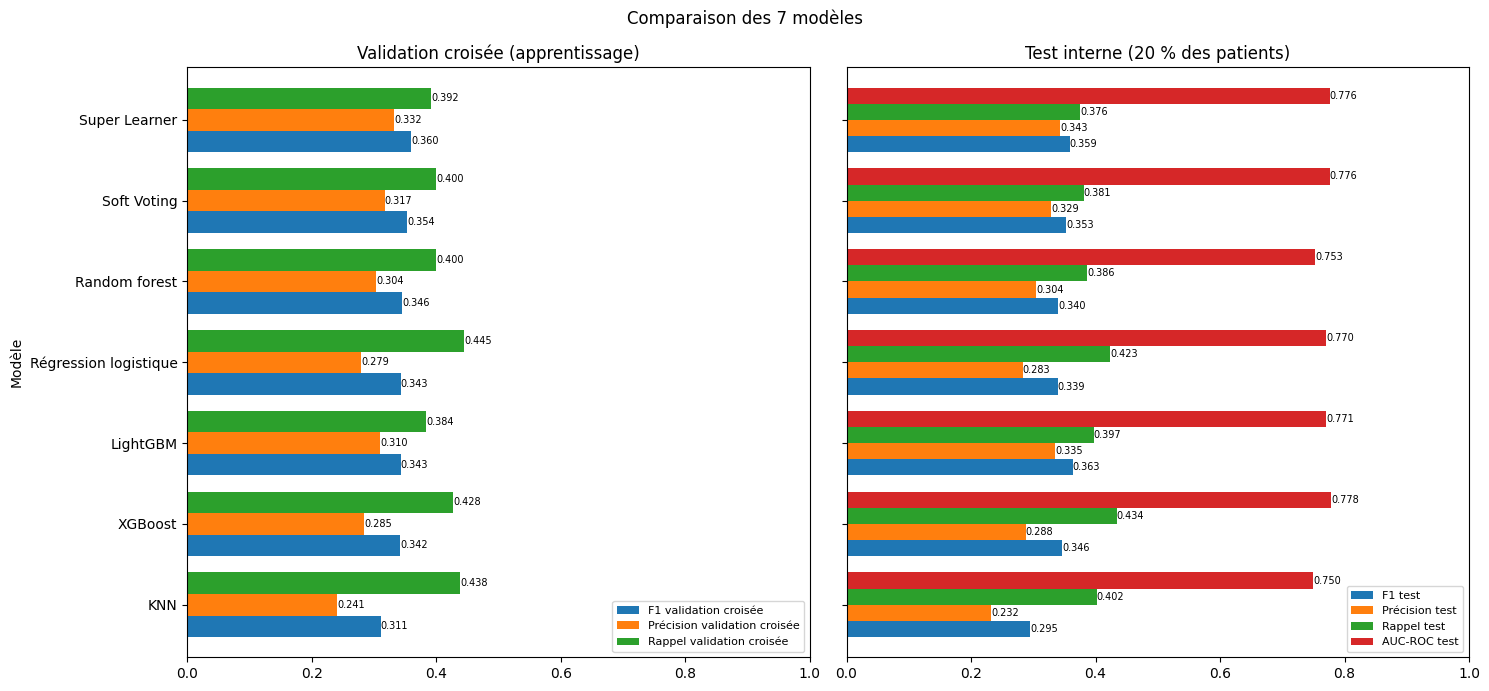

Modèle final : Super Learner | seuil = 0.15


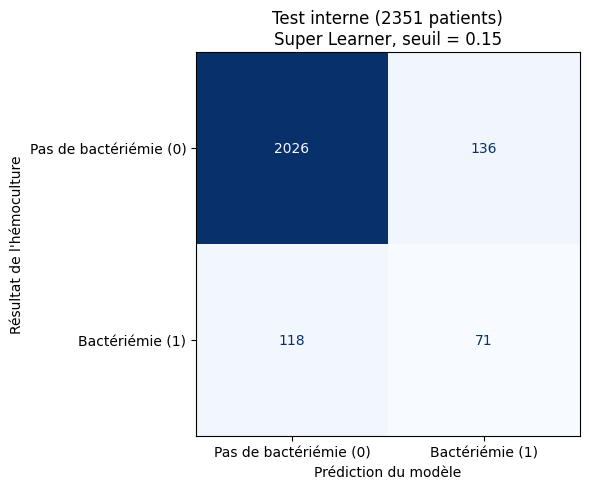

VP = 71 | FN = 118 | FP = 136 | VN = 2026
Sensibilité (rappel) = 0.376 | Spécificité = 0.937
VPP (précision) = 0.343 | VPN = 0.945
F1 = 0.359 (identique au F1 test du tableau de l'étape 7)
Régression logistique    3.02
KNN                      3.72
LightGBM                 4.07
dtype: float64


In [10]:
import matplotlib.pyplot as plt
from sklearn.base import clone
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#Ordre des modèles : meilleur F1 en validation croisée en haut
ordre = resultats.sort_values("F1 validation croisée").index
scores_cv = resultats.loc[ordre, ["F1 validation croisée", "Précision validation croisée", "Rappel validation croisée"]]
scores_test = resultats.loc[ordre, ["F1 test", "Précision test", "Rappel test", "AUC-ROC test"]]

#Deux graphiques côte à côte : validation croisée à gauche, test à droite
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 7), sharey=True)
scores_cv.plot(kind="barh", ax=ax1, width=0.8, xlim=(0, 1), title="Validation croisée (apprentissage)")
scores_test.plot(kind="barh", ax=ax2, width=0.8, xlim=(0, 1), title="Test interne (20 % des patients)")
for ax in (ax1, ax2):
    for barres in ax.containers:
        ax.bar_label(barres, fmt="%.3f", fontsize=7)   #écrit la valeur au bout de chaque barre
    ax.legend(loc="lower right", fontsize=8)
fig.suptitle("Comparaison des 7 modèles")
plt.tight_layout()
plt.savefig("comparaison_modeles.png", dpi=150)
plt.show()

#Modèle final = meilleur F1 en validation croisée
nom_final = resultats["F1 validation croisée"].idxmax()
print("Modèle final :", nom_final, "| seuil =", round(seuils[nom_final], 2))

#Matrice de confusion sur le test interne
#copie du modèle final entraînée seulement sur l'apprentissage
#(le modèle final, lui, est réentraîné plus bas sur tous les patients, test interne compris)
modele_eval = clone(modeles[nom_final]).fit(X_train, y_train)
pred_final_test = (modele_eval.predict_proba(X_test)[:, 1] >= seuils[nom_final]).astype(int)

mc = confusion_matrix(y_test, pred_final_test)   #lignes = réalité, colonnes = prédiction
vn, fp, fn, vp = mc.ravel()

fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(mc, display_labels=["Pas de bactériémie (0)", "Bactériémie (1)"]).plot(
    ax=ax, cmap="Blues", colorbar=False, values_format="d")
ax.set_xlabel("Prédiction du modèle")
ax.set_ylabel("Résultat de l'hémoculture")
ax.set_title(f"Test interne ({len(y_test)} patients)\n{nom_final}, seuil = {seuils[nom_final]:.2f}")
plt.tight_layout()
plt.savefig("matrice_confusion.png", dpi=150)
plt.show()

print(f"VP = {vp} | FN = {fn} | FP = {fp} | VN = {vn}")
print(f"Sensibilité (rappel) = {vp / (vp + fn):.3f} | Spécificité = {vn / (vn + fp):.3f}")
print(f"VPP (précision) = {vp / (vp + fp):.3f} | VPN = {vn / (vn + fn):.3f}")
print(f"F1 = {f1_score(y_test, pred_final_test):.3f} (identique au F1 test du tableau de l'étape 7)")

#Modèle final réentraîné sur tous les patients
modele_final = modeles[nom_final].fit(X, y)

#Si c'est le Super Learner : poids donnés à chaque modèle par le méta-modèle
if nom_final == "Super Learner":
    print(pd.Series(modele_final.final_estimator_.coef_[0], index=familles).round(2))

## 9. prédire le fichier de test
* On lit le fichier à prédire "bacteriemie_test.csv.gz" , 2 938 nouveaux patients sans la colonne BloodCulture et on lui applique le même nettoyage que les données d'apprentissage.
* Le modèle final donne une probabilité de bactériémie pour chaque patient et avec le seuil on obtient **0 ou 1**.
* On enregistre un fichier .csv à 2 colonnes `ID` et `pred`.  Si le fichier n'a pas la colonne ID, on numérote les patients.

In [11]:
#lecture du fichier à prédire et même nettoyage que les données d'apprentissage
df_test = nettoyer(pd.read_csv(fichier_test))

#Mêmes variables que pour l'apprentissage, dans le même ordre
# (une variable absente devient NaN, les colonnes en trop, comme BloodCulture, sont ignorées)
X_nouveau = df_test.reindex(columns=X.columns)

#Probabilité de bactériémie pour chaque patient
probabilite = modele_final.predict_proba(X_nouveau)[:, 1]

#Décision 0/1 : 1 si la probabilité dépasse le seuil du modèle final, sinon 0
prediction = (probabilite >= seuils[nom_final]).astype(int)

#Identifiants : colonne ID du fichier si elle existe, sinon 1, 2, 3...
if "ID" in df_test:
    ids = df_test["ID"]
else:
    ids = np.arange(1, len(df_test) + 1)

#Fichier de prédiction : 2 colonnes, ID et pred
pd.DataFrame({"ID": ids, "pred": prediction}).to_csv(fichier_sortie, index=False)
print(len(df_test), "patients prédits dont", prediction.sum(), "bactériémies ->", fichier_sortie)

2938 patients prédits dont 284 bactériémies -> groupe4_ABAKAR_ASAS_SAAD_SOYLU_BOUGHANEM_MOUYANSELE.csv
